In [3]:
"""
Student Performance Analysis
Objective: Analyze student data to identify patterns and factors associated with
academic performance - attendance, study habits, assessment scores, final results.

Tools: Python, Pandas, NumPy, Matplotlib, Scikit-learn,
       Linear Regression, Random Forest
Run:   python student_performance_analysis.py
Output: graphs in 'graphs' folder + student_data_cleaned.csv
"""

import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score, confusion_matrix

plt.style.use("ggplot")
os.makedirs("graphs", exist_ok=True)
np.random.seed(42)
BLUE = "#2E75B6"


def save(name):
    plt.tight_layout()
    plt.savefig(f"graphs/{name}.png", dpi=150)
    plt.close()


def scatter_with_line(x, y, title, xlabel, color):
    """Scatter plot with a red trend line."""
    plt.figure(figsize=(8, 5))
    plt.scatter(x, y, alpha=0.4, color=color)
    m, c = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    plt.plot(xs, m * xs + c, color="red", linewidth=2)
    plt.title(title); plt.xlabel(xlabel); plt.ylabel("Final Score")


# ------------------------------------------------------------------
# STEP 1: Dataset (if you have a real CSV, use: df = pd.read_csv("your_file.csv"))
# ------------------------------------------------------------------
n = 500
df = pd.DataFrame({
    "StudentID": range(1, n + 1),
    "Gender": np.random.choice(["Male", "Female"], n),
    # Attendance
    "Attendance": np.round(np.random.uniform(45, 100, n), 1),
    # Study habits
    "StudyHours": np.round(np.random.uniform(1, 10, n), 1),
    "SleepHours": np.round(np.random.uniform(4, 9, n), 1),
    "RegularRevision": np.random.choice(["Yes", "No"], n, p=[0.55, 0.45]),
    "GroupStudy": np.random.choice(["Yes", "No"], n, p=[0.4, 0.6]),
})

ability = (0.5 * df["StudyHours"] * 4 + 0.3 * df["Attendance"]
           + np.where(df["RegularRevision"] == "Yes", 6, 0)
           + np.random.normal(0, 6, n))
# Assessment scores (out of 100)
df["Assignment"] = (ability * 0.9 + np.random.normal(0, 5, n) + 38).clip(0, 100).round(1)
df["Quiz"] = (ability * 0.9 + np.random.normal(0, 7, n) + 34).clip(0, 100).round(1)
df["Midterm"] = (ability * 0.95 + np.random.normal(0, 6, n) + 32).clip(0, 100).round(1)
# Final result
df["FinalScore"] = (0.2 * df["Assignment"] + 0.2 * df["Quiz"] + 0.3 * df["Midterm"]
                    + 0.15 * df["Attendance"] + 1.0 * df["StudyHours"]
                    + np.random.normal(0, 3, n) + 8).clip(0, 100).round(1)

# Add a few missing values (to demonstrate data cleaning)
for col in ["SleepHours", "Attendance", "Quiz"]:
    df.loc[df.sample(frac=0.03).index, col] = np.nan

# ------------------------------------------------------------------
# STEP 2: Data Cleaning
# ------------------------------------------------------------------
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
for col in ["SleepHours", "Attendance", "Quiz"]:
    df[col] = df[col].fillna(df[col].median())
df = df.drop_duplicates()
print("Missing after cleaning:", int(df.isnull().sum().sum()))


def grade(s):
    return "A" if s >= 80 else "B" if s >= 70 else "C" if s >= 60 else "Fail"


df["Grade"] = df["FinalScore"].apply(grade)
df["Result"] = np.where(df["FinalScore"] >= 60, "Pass", "Fail")
df["AttendanceLevel"] = pd.cut(df["Attendance"], [0, 60, 75, 100],
                               labels=["Low (<60)", "Medium (60-75)", "High (>75)"])
df.to_csv("student_data_cleaned.csv", index=False)

# ------------------------------------------------------------------
# STEP 3: Descriptive statistics + key patterns
# ------------------------------------------------------------------
print("\nSummary statistics:\n", df.describe().round(2))
print("\nPass percentage: %.1f%%" % ((df["Result"] == "Pass").mean() * 100))
print("\nAvg final score by Attendance level:\n",
      df.groupby("AttendanceLevel", observed=True)["FinalScore"].mean().round(2))
print("\nAvg final score by Regular Revision:\n",
      df.groupby("RegularRevision")["FinalScore"].mean().round(2))
num_cols = ["Attendance", "StudyHours", "SleepHours", "Assignment", "Quiz", "Midterm", "FinalScore"]
corr = df[num_cols].corr()
print("\nCorrelation with FinalScore:\n",
      corr["FinalScore"].drop("FinalScore").sort_values(ascending=False).round(2))

# ------------------------------------------------------------------
# STEP 4: Visualizations (Matplotlib)
# ------------------------------------------------------------------
# 1. Score distribution
plt.figure(figsize=(8, 5))
plt.hist(df["FinalScore"], bins=20, color=BLUE, edgecolor="white")
plt.title("Distribution of Final Scores"); plt.xlabel("Final Score"); plt.ylabel("Number of Students")
save("1_score_distribution")
plt.show()

# 2. Attendance vs Final Score
scatter_with_line(df["Attendance"], df["FinalScore"], "Attendance vs Final Score", "Attendance (%)", "green")
save("2_attendance_vs_score")
plt.show()

# 3. Study Hours vs Final Score
scatter_with_line(df["StudyHours"], df["FinalScore"], "Study Hours vs Final Score", "Study Hours per Day", BLUE)
save("3_studyhours_vs_score")
plt.show()

# 4. Effect of regular revision
plt.figure(figsize=(7, 5))
rev = df.groupby("RegularRevision")["FinalScore"].mean()
plt.bar(rev.index, rev.values, color=["#E57373", "#4CAF50"])
for i, v in enumerate(rev.values):
    plt.text(i, v + 0.5, "%.1f" % v, ha="center")
plt.title("Final Score: Regular Revision vs Not"); plt.ylabel("Average Final Score")
save("4_revision_effect")
plt.show()

# 5. Final score by attendance level (boxplot)
plt.figure(figsize=(8, 5))
levels = ["Low (<60)", "Medium (60-75)", "High (>75)"]
plt.boxplot([df.loc[df["AttendanceLevel"] == l, "FinalScore"] for l in levels],
            patch_artist=True, boxprops=dict(facecolor="#9CC3E6"))
plt.xticks([1, 2, 3], levels)
plt.title("Final Score by Attendance Level"); plt.ylabel("Final Score")
save("5_attendance_level_boxplot")
plt.show()

# 6. Average assessment scores
plt.figure(figsize=(8, 5))
avg = df[["Assignment", "Quiz", "Midterm", "FinalScore"]].mean()
plt.bar(avg.index, avg.values, color=BLUE)
for i, v in enumerate(avg.values):
    plt.text(i, v + 0.5, "%.1f" % v, ha="center")
plt.title("Average Assessment Scores"); plt.ylabel("Average Score")
save("6_assessment_averages")
plt.show()

# 7. Grade distribution (pie)
plt.figure(figsize=(6, 6))
gc = df["Grade"].value_counts()
plt.pie(gc.values, labels=gc.index, autopct="%1.1f%%", startangle=90,
        colors=["#4CAF50", "#2196F3", "#FFC107", "#F44336"][:len(gc)])
plt.title("Grade Distribution")
save("7_grade_pie")
plt.show()

# 8. Correlation heatmap
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
plt.yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        plt.text(j, i, "%.2f" % corr.iloc[i, j], ha="center", va="center", fontsize=8)
plt.grid(False)
plt.title("Correlation Heatmap")
save("8_correlation_heatmap")
plt.show()

# ------------------------------------------------------------------
# STEP 5: Machine Learning (Scikit-learn)
# ------------------------------------------------------------------
features = ["Gender", "Attendance", "StudyHours", "SleepHours", "RegularRevision",
            "GroupStudy", "Assignment", "Quiz", "Midterm"]
X = pd.get_dummies(df[features], drop_first=True)

# (a) Linear Regression: predict FinalScore
X_tr, X_te, y_tr, y_te = train_test_split(X, df["FinalScore"], test_size=0.2, random_state=42)
lr = LinearRegression().fit(X_tr, y_tr)
pred = lr.predict(X_te)
print("\n--- Linear Regression ---")
print("R2 Score: %.3f" % r2_score(y_te, pred))
print("MAE     : %.2f" % mean_absolute_error(y_te, pred))

# 9. Actual vs Predicted
plt.figure(figsize=(7, 6))
plt.scatter(y_te, pred, alpha=0.5, color=BLUE)
plt.plot([0, 100], [0, 100], "r--")
plt.xlabel("Actual Score"); plt.ylabel("Predicted Score")
plt.title("Actual vs Predicted (Linear Regression)")
save("9_actual_vs_predicted")
plt.show()

# (b) Random Forest: classify Pass/Fail
yc = (df["Result"] == "Pass").astype(int)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X, yc, test_size=0.2, random_state=42)
rf = RandomForestClassifier(n_estimators=150, random_state=42).fit(Xc_tr, yc_tr)
pc = rf.predict(Xc_te)
print("\n--- Random Forest (Pass/Fail) ---")
print("Accuracy: %.3f" % accuracy_score(yc_te, pc))

# 10. Confusion matrix
cm = confusion_matrix(yc_te, pc)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.xticks([0, 1], ["Fail", "Pass"]); plt.yticks([0, 1], ["Fail", "Pass"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.grid(False)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
save("10_confusion_matrix")
plt.show()

# 11. Feature importance (Random Forest)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(imp.index, imp.values, color=BLUE)
plt.title("Feature Importance: What affects performance most?")
plt.xlabel("Importance")
save("11_feature_importance")
plt.show()

print("\nDone! 11 graphs saved in the 'graphs' folder.")

Shape: (500, 11)

Missing values:
 Attendance    15
SleepHours    15
Quiz          15
dtype: int64
Missing after cleaning: 0

Summary statistics:
        StudentID  Attendance  StudyHours  SleepHours  Assignment    Quiz  \
count     500.00      500.00      500.00      500.00      500.00  500.00   
mean      250.50       72.36        5.58        6.44       70.41   66.89   
std       144.48       15.89        2.66        1.42       10.10   11.56   
min         1.00       45.60        1.00        4.00       40.50   33.00   
25%       125.75       58.88        3.10        5.20       63.90   59.00   
50%       250.50       72.60        5.75        6.50       70.60   67.10   
75%       375.25       86.12        7.90        7.50       77.60   74.22   
max       500.00      100.00       10.00        9.00       96.30  100.00   

       Midterm  FinalScore  
count   500.00      500.00  
mean     66.11       71.47  
std      11.31       10.30  
min      26.80       39.80  
25%      58.20       64

Total graphs found: 11
10_confusion_matrix.png


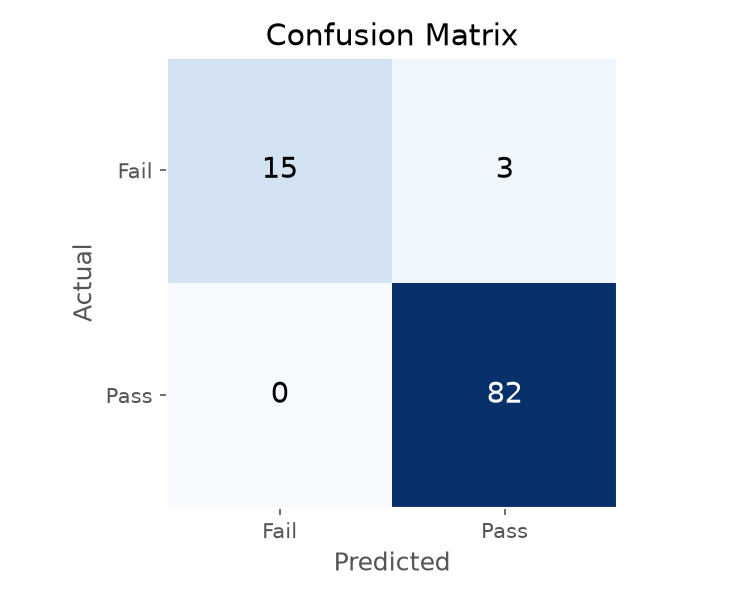

11_feature_importance.png


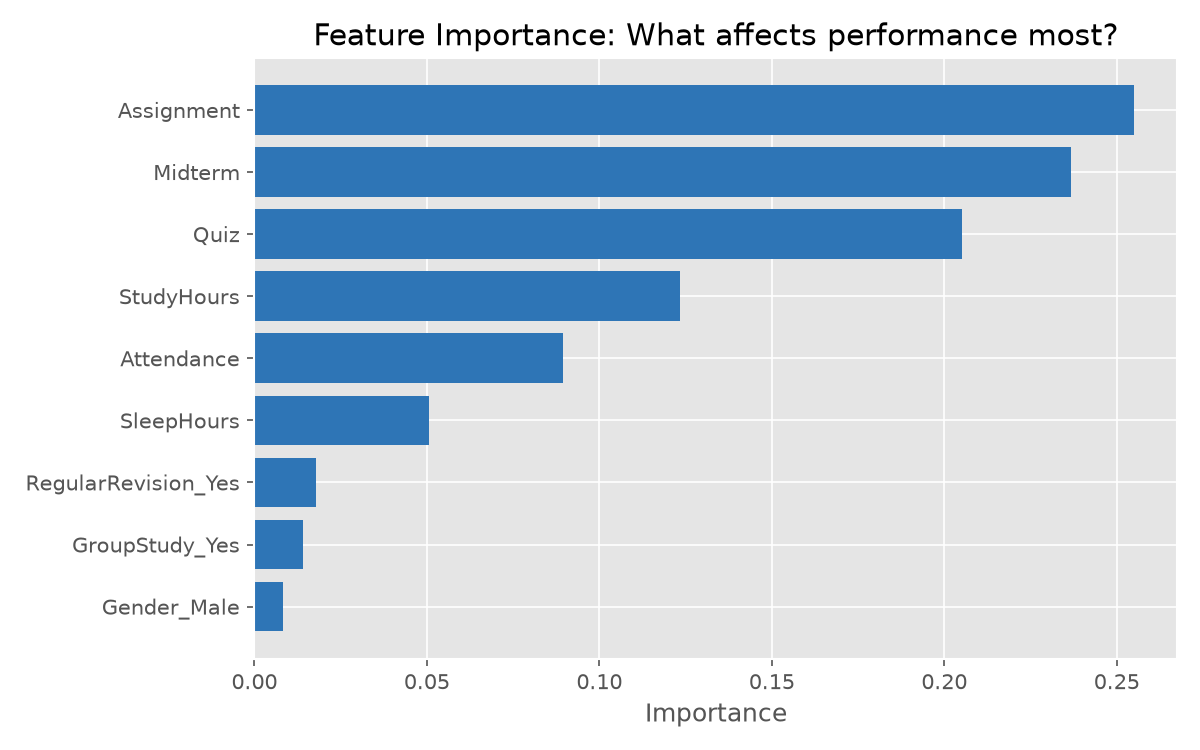

1_score_distribution.png


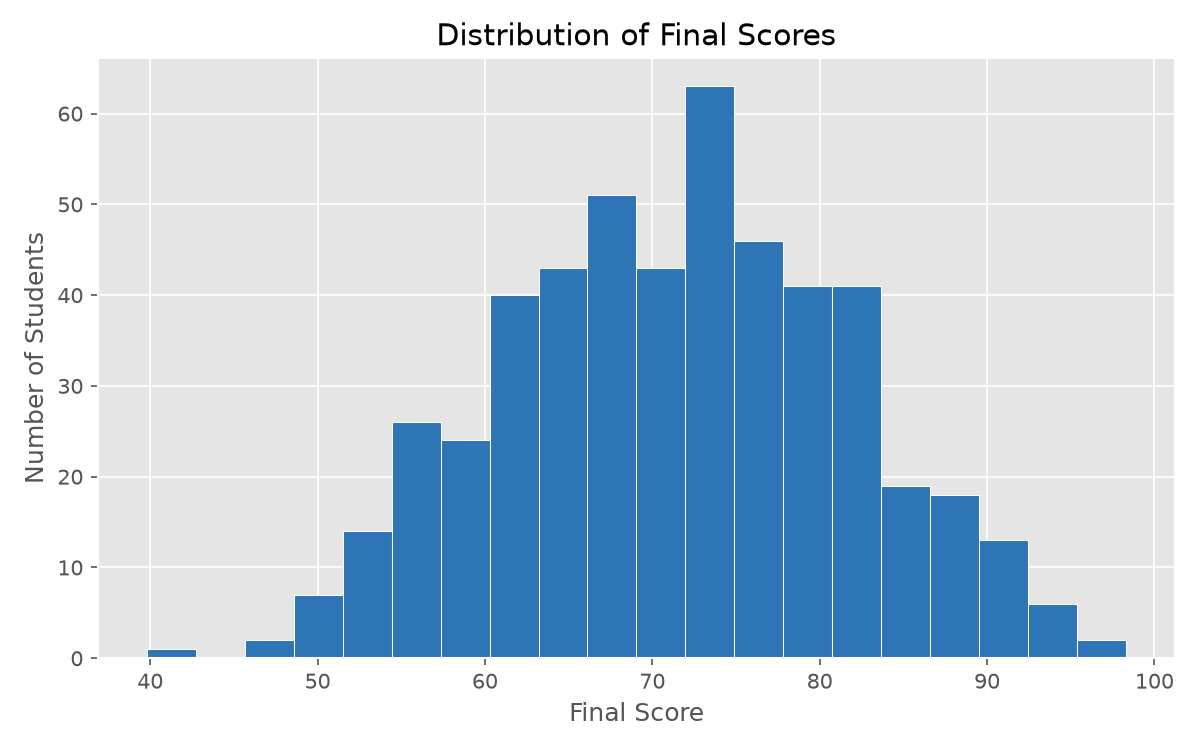

2_attendance_vs_score.png


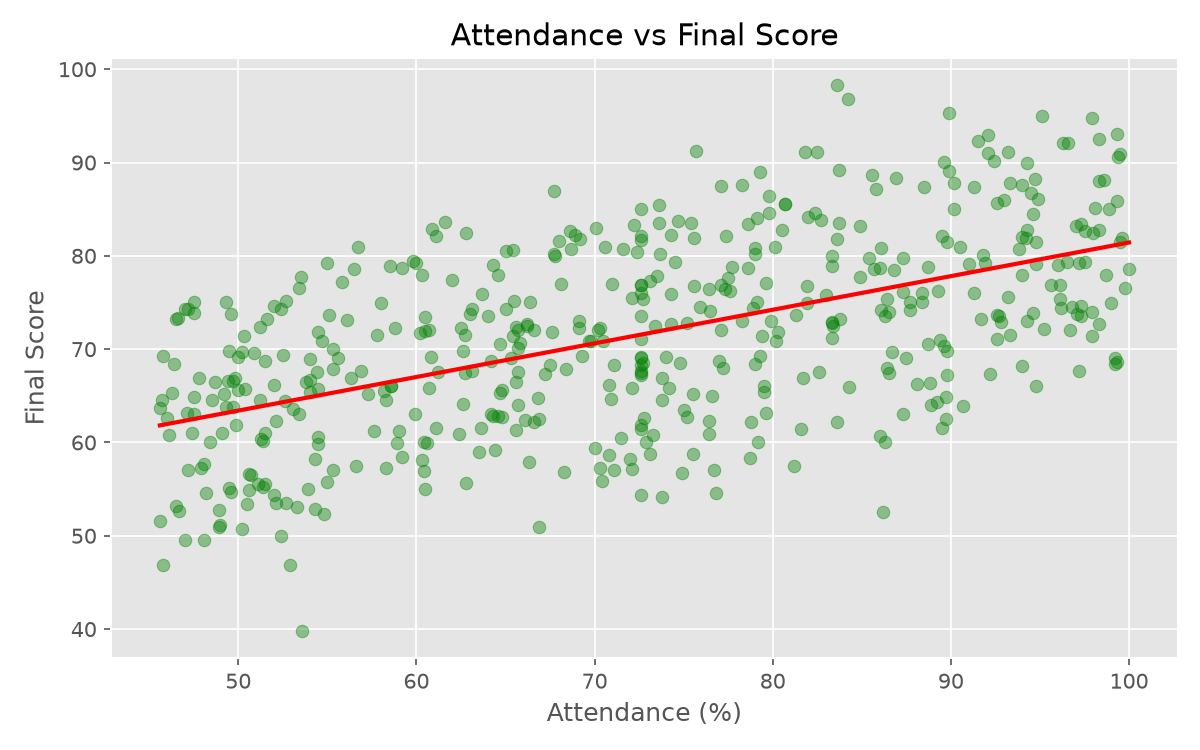

3_studyhours_vs_score.png


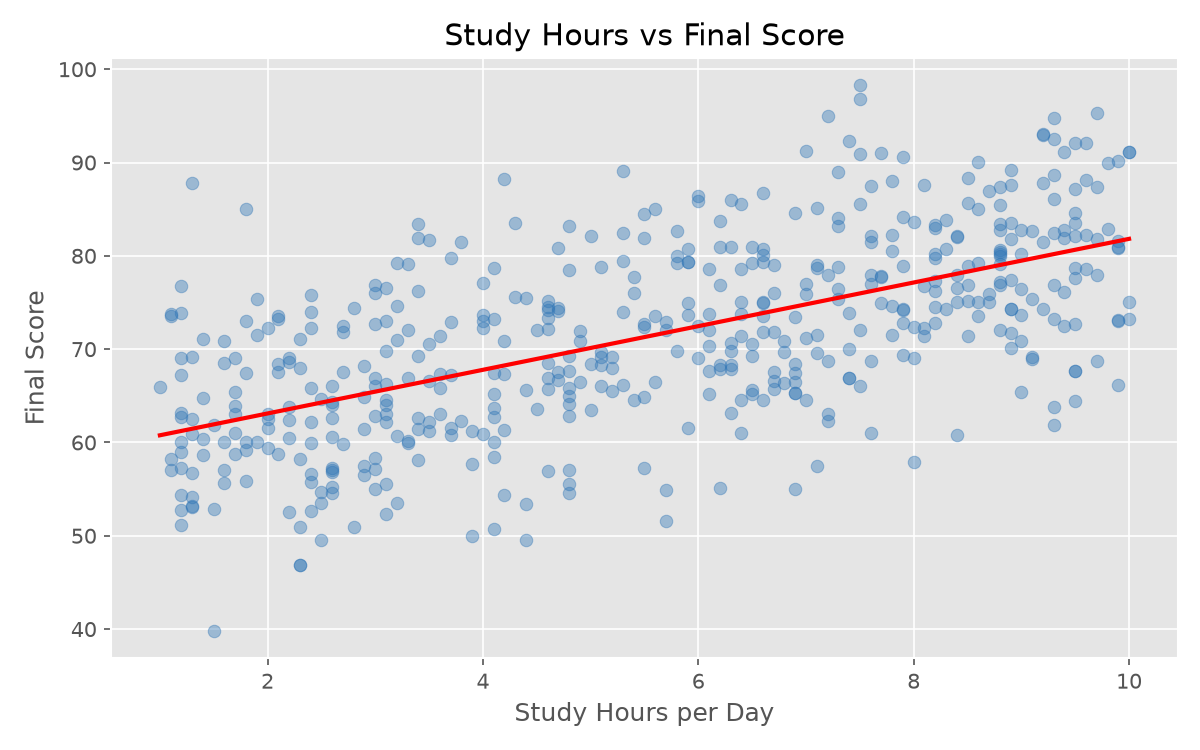

4_revision_effect.png


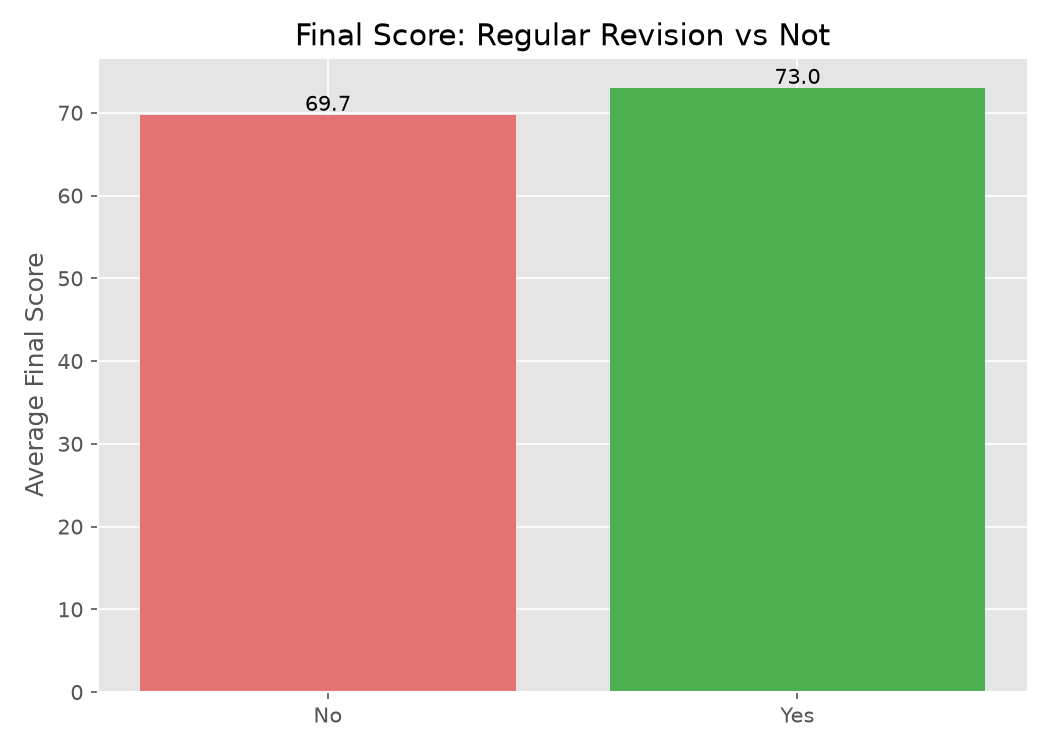

5_attendance_level_boxplot.png


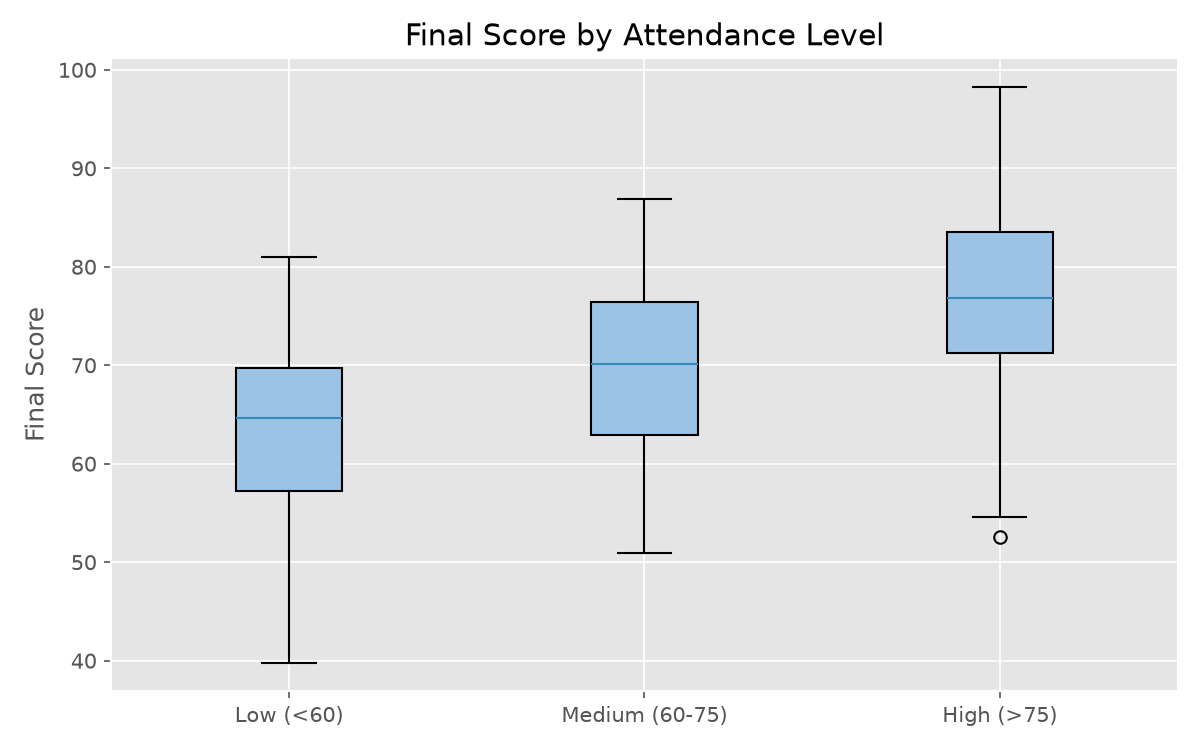

6_assessment_averages.png


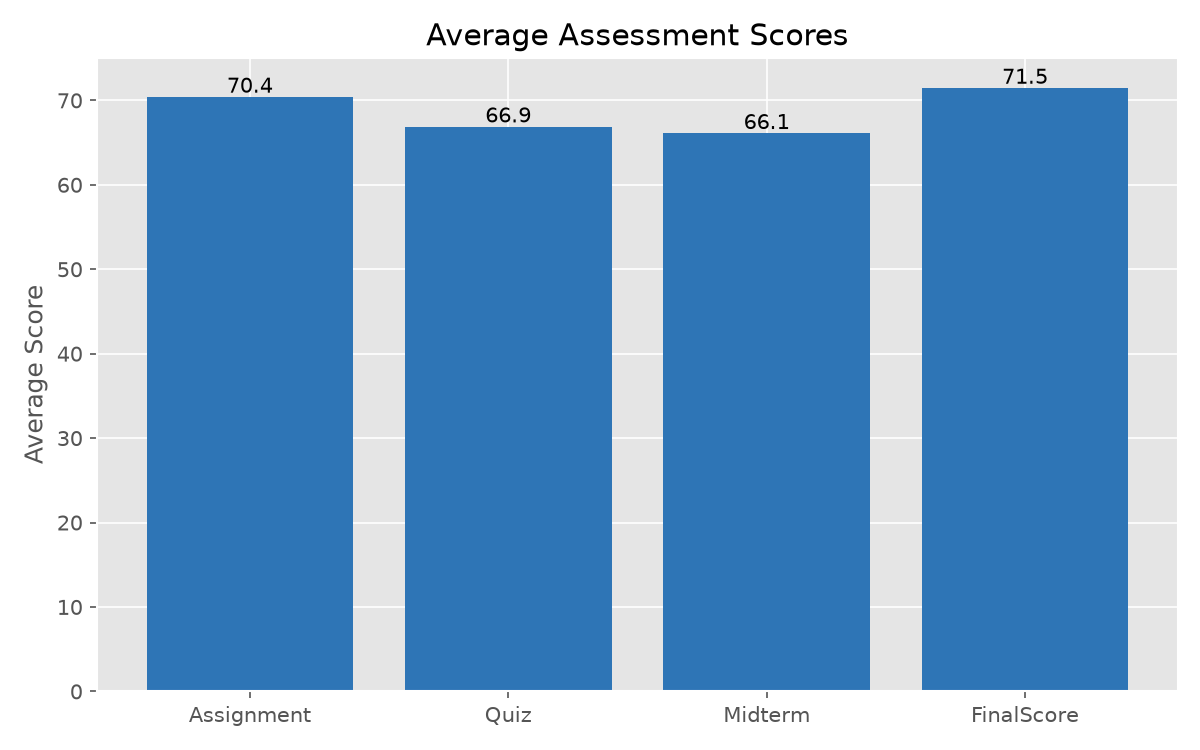

7_grade_pie.png


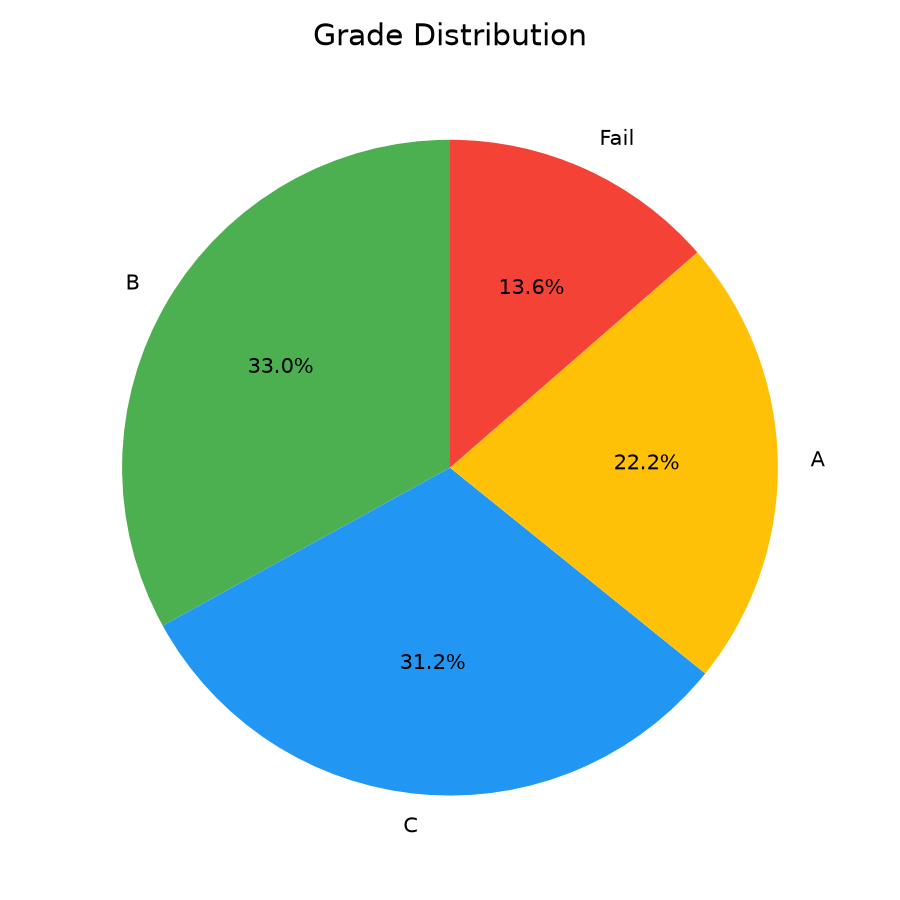

8_correlation_heatmap.png


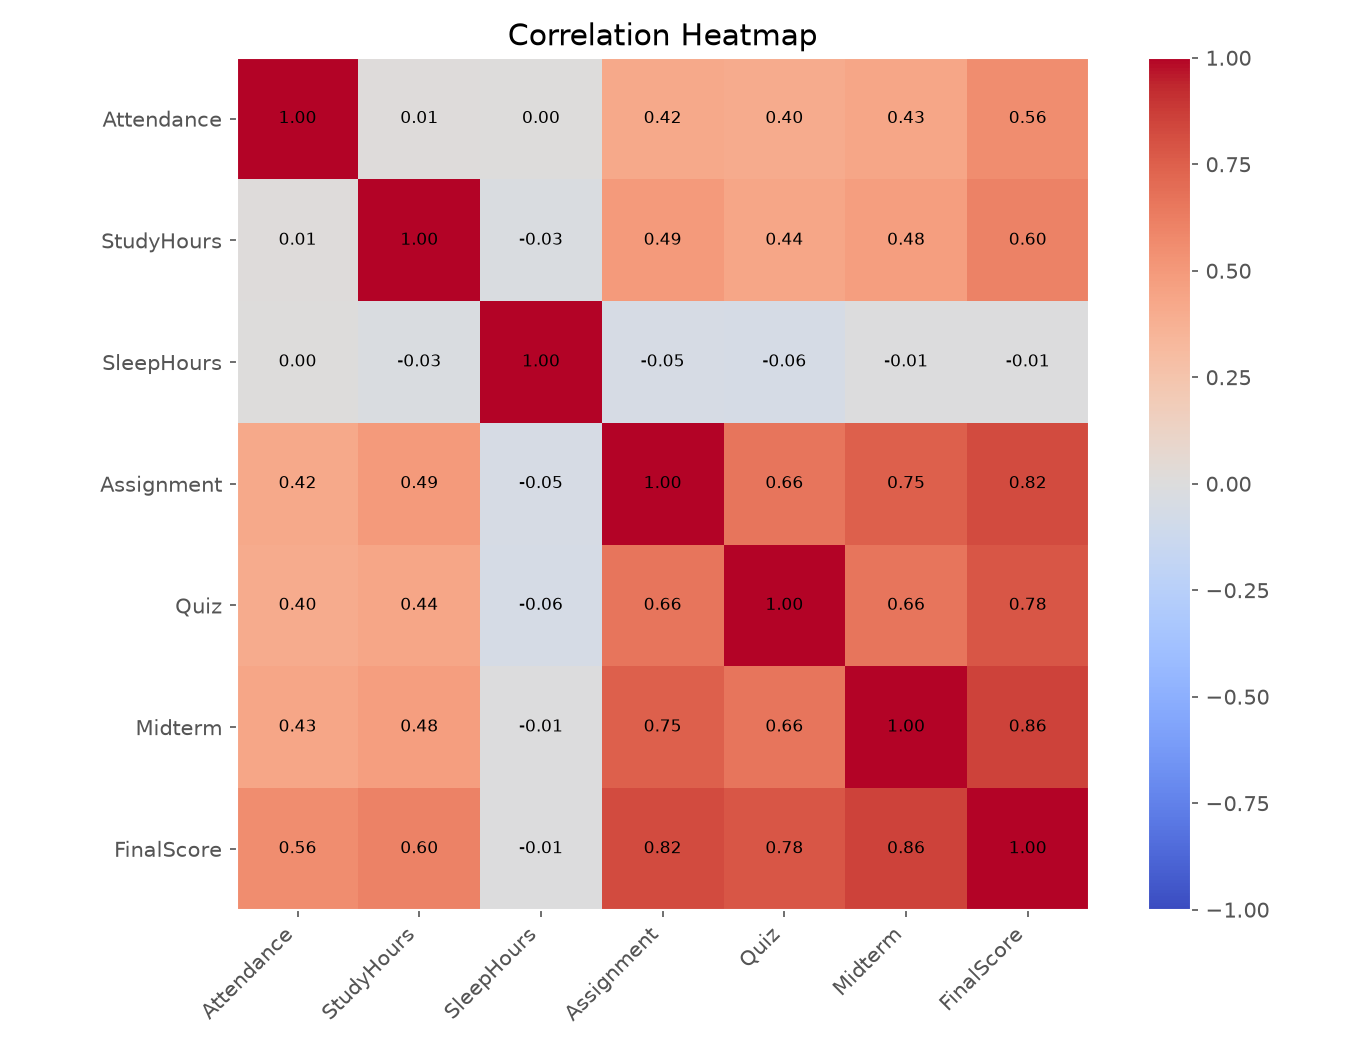

9_actual_vs_predicted.png


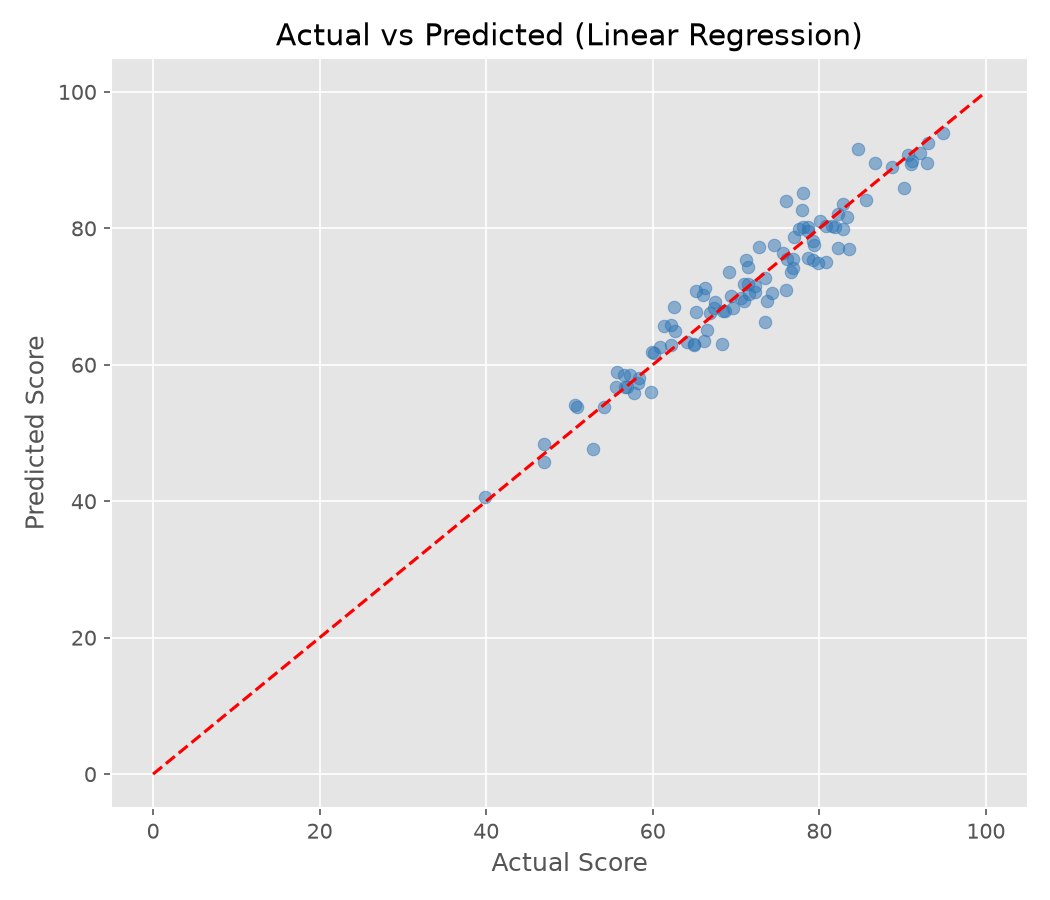

In [4]:

import os
import glob
from IPython.display import Image, display

graph_files = sorted(glob.glob("graphs/*.png"))

print("Total graphs found:", len(graph_files))

for graph in graph_files:
    print(os.path.basename(graph))
    display(Image(filename=graph))
